# Sites, coverage and data quality

Skillmap stratifies sites by Köppen class, with climate-group quotas, rare-class coverage
and geographic spread. Cities and research stations share the same data contract.
The sample is designed for climate comparisons; it is not weighted by population or land area.
See `contracts/README.md` and `src/skillmap/sites.py` for the exact selection rules.
The coverage audit records absent classes without assigning invented classifications.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))
from skillmap.config import PROCESSED, FIGURES, SPLITS, WEATHER_COLUMNS
findings = json.loads((PROCESSED / 'findings.json').read_text())
sites = pd.read_csv(PROCESSED / 'sites.csv', keep_default_na=False)
predictions = pd.read_parquet(PROCESSED / 'predictions.parquet')
selected = sites[sites.site_id.isin(findings['site_ids'])]
display(Markdown(f"This run evaluates **{findings['n_sites']} complete sites**. "
                 f"The full sampling frame contains **{len(sites)} sites**."))

This run evaluates **200 complete sites**. The full sampling frame contains **200 sites**.

,koppen_code,koppen,koppen_group,n_candidates,n_selected,countries
0,1,Af,A,1506,7,BR;ID;MY;PR;SG
1,2,Am,A,1830,6,BR;CI;IN;MU;MV
2,3,Aw,A,5839,22,AU;BR;BS;CD;CM;GM;ID;IN;MZ;NG;NI;SO;SS;TZ;US;V...
3,4,BWh,B,1504,15,AE;AO;EG;EH;IR;LY;MX;NA;NE;PK;SA;SD;SO;TD
4,5,BWk,B,300,5,CL;CN;KZ;UZ
5,6,BSh,B,2230,11,ET;IN;LY;MA;MG;ML;MM;PK;VE;ZW
6,7,BSk,B,1184,9,AR;CA;CN;ES;IR;KZ;US
7,8,Csa,C,2095,5,AL;AU;IT;TR;US
8,9,Csb,C,643,8,AU;CL;CM;EC;ES;PT;US;ZA
9,10,Csc,C,1,1,PE


,evaluated_sites
koppen_group,
A,35
B,40
C,60
D,50
E,15


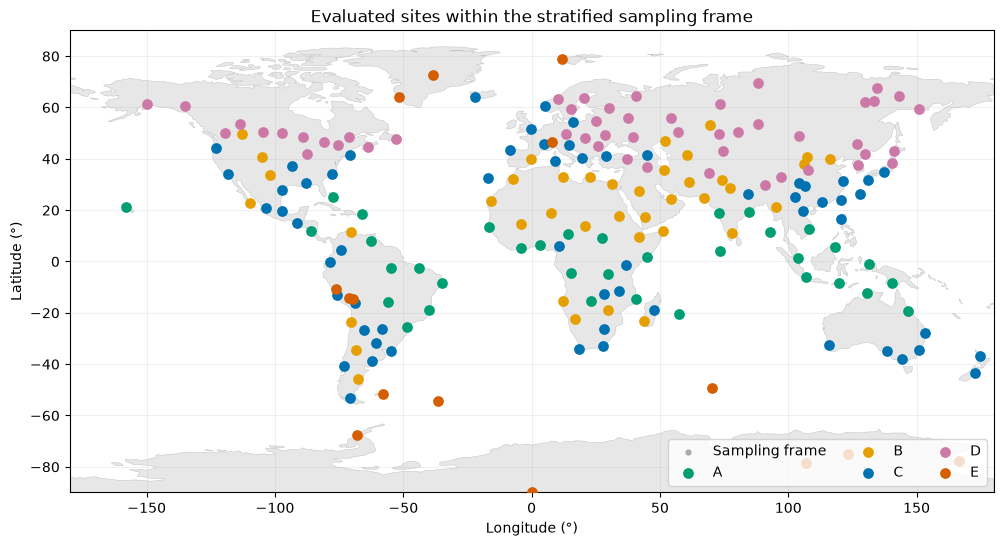

In [2]:
coverage = pd.read_csv(PROCESSED / 'koppen_coverage.csv')
display(coverage)
display(selected.groupby('koppen_group').size().rename('evaluated_sites').to_frame())
from scripts.make_figures import land, COLORS
fig, ax = plt.subplots(figsize=(12, 6))
land(ax)
ax.scatter(sites.lon, sites.lat, s=12, color='#aaaaaa', label='Sampling frame')
for group, frame in selected.groupby('koppen_group'):
    ax.scatter(frame.lon, frame.lat, s=45, color=COLORS[group], label=group, zorder=3)
ax.set_title('Evaluated sites within the stratified sampling frame')
ax.legend(ncols=3)
plt.show()

## Data QA

`daily.parquet` keeps complete calendars even for partially downloaded histories. The QA
below reports the entire available table and the evaluated subset separately. Observed
ranges are sanity checks, not assertions that all real weather falls within fixed limits.

,fraction_finite_tmax
site_id,
gn-1006984,1.0
gn-1035025,1.0
gn-103630,1.0
gn-1055429,1.0
gn-106281,1.0
...,...
st-ny-alesund,1.0
st-rothera,1.0
st-south-pole,1.0


,missing_all,missing_evaluated,min_evaluated,max_evaluated,median_evaluated,unit
tmax,0.0,0.0,-73.30,49.70,22.60,°C
tmin,0.0,0.0,-77.50,37.50,13.20,°C
rh_mean,0.0,0.0,4.00,100.00,74.00,%
msl_mean,0.0,0.0,943.00,1066.70,1013.80,hPa
wind_mean,0.0,0.0,0.07,26.43,2.75,m/s


,count
duplicate_site_dates,0
tmin_above_tmax,0
humidity_outside_0_100,0
negative_wind,0


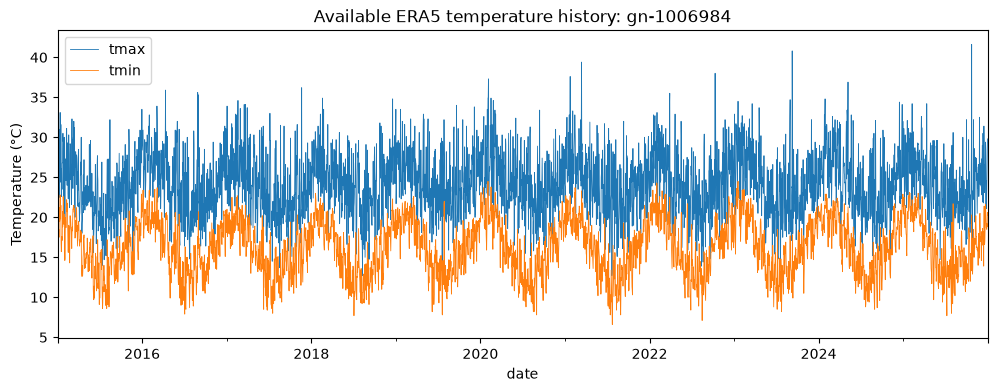

In [3]:
daily = pd.read_parquet(PROCESSED / 'daily.parquet')
daily['date'] = pd.to_datetime(daily.date)
complete = daily.groupby('site_id').tmax.apply(lambda x: x.notna().mean())
display(complete.rename('fraction_finite_tmax').sort_values().to_frame())
evaluated = daily[daily.site_id.isin(findings['site_ids'])]
qa = pd.DataFrame({
    'missing_all': daily[WEATHER_COLUMNS].isna().mean(),
    'missing_evaluated': evaluated[WEATHER_COLUMNS].isna().mean(),
    'min_evaluated': evaluated[WEATHER_COLUMNS].min(),
    'max_evaluated': evaluated[WEATHER_COLUMNS].max(),
    'median_evaluated': evaluated[WEATHER_COLUMNS].median(),
    'unit': ['°C', '°C', '%', 'hPa', 'm/s'],
})
display(qa)
display(pd.Series({
    'duplicate_site_dates': int(daily.duplicated(['site_id', 'date']).sum()),
    'tmin_above_tmax': int((evaluated.tmin > evaluated.tmax).sum()),
    'humidity_outside_0_100': int((~evaluated.rh_mean.between(0,100)
                                   & evaluated.rh_mean.notna()).sum()),
    'negative_wind': int(evaluated.wind_mean.lt(0).sum()),
}).to_frame('count'))
sample_id = findings['site_ids'][0]
sample = evaluated[evaluated.site_id == sample_id].sort_values('date')
ax = sample.plot(x='date', y=['tmax', 'tmin'], figsize=(12,4), linewidth=0.6)
ax.set(title=f'Available ERA5 temperature history: {sample_id}', ylabel='Temperature (°C)')
plt.show()

## API and interpretation caveats

These are ERA5 reanalysis daily aggregates at an API grid cell, not independent station
observations or an operational forecast archive. Grid-cell elevation and coordinates can
differ from the selected site. Lagged reanalysis is a retrospective predictability experiment;
real-time reporting latency and forecast availability are not simulated.

`timezone=auto` yields local calendar dates, but local-day boundaries are fixed at the
request-time UTC offset; historical daylight-saving transitions are not reconstructed.
Cached response metadata records the returned timezone and offset. Temperature is in °C,
humidity in %, mean sea-level pressure in hPa, and wind speed in m/s.

In [4]:
meta = pd.read_csv(PROCESSED / 'api_meta.csv')
display(meta[meta.site_id.isin(findings['site_ids'])])

,site_id,grid_lat,grid_lon,grid_elevation,timezone,utc_offset_seconds
0,gn-3946938,-13.00,-75.75,3393.0,America/Lima,-18000
1,st-vostok,-78.50,106.75,3497.0,Antarctica/Vostok,18000
2,st-mcmurdo,-78.00,166.75,125.0,Antarctica/McMurdo,46800
3,gn-2120048,64.50,143.25,485.0,Asia/Ust-Nera,36000
4,gn-2012874,62.25,133.50,152.0,Asia/Yakutsk,32400
...,...,...,...,...,...,...
195,st-summit,72.50,-38.50,3208.0,America/Nuuk,-3600
196,gn-3426691,-51.75,-57.75,13.0,Atlantic/Stanley,-10800
197,st-concordia,-75.00,123.25,3270.0,Australia/Perth,28800
198,st-jungfraujoch,46.50,8.00,3484.0,Europe/Zurich,3600
